# Radar rainfall against gauges

Compare nearby gauges with radar, select station-days with good correlation, and inspect the effect of a 13 dB offset. Gauge measurements are 10-minute accumulations: multiply by 6 for mm/hr.

## 1. Imports and data


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from pacha.L2_processing import radar as l2rad
from pacha.utils import file_utils as futils
from pacha.utils import geospatial as gutils
from pacha.utils import instruments as iutils

In [2]:
l1_rad_dir = '/home/admingosset/WORK/projects/funceme-radar-qpe/data/processed/l1_radar/'
gauges_data_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc.csv'
gauges_metadata_path = '/media/admingosset/T7Shield/data/processed_data/ceara/gauges/v0/gauges_10min_utc_metadata.csv'

gauges = iutils.Gauges(gauges_data_path, gauges_metadata_path)
df_fpaths_l1rad = futils.get_df_dates_filepaths(
    l1_rad_dir, date_char_st=9, date_char_nd=19, date_format='%Y_%m_%d'
)

with xr.open_dataset(df_fpaths_l1rad.iloc[0, 0]) as sample_ds:
    lon0, lat0 = gutils.calc_ds_center(sample_ds)

print(f'Radar center: ({lon0}, {lat0})')

Radar center: (-39.26805152577293, -5.070284552413706)


## 2. Nearby gauges and daily rainfall


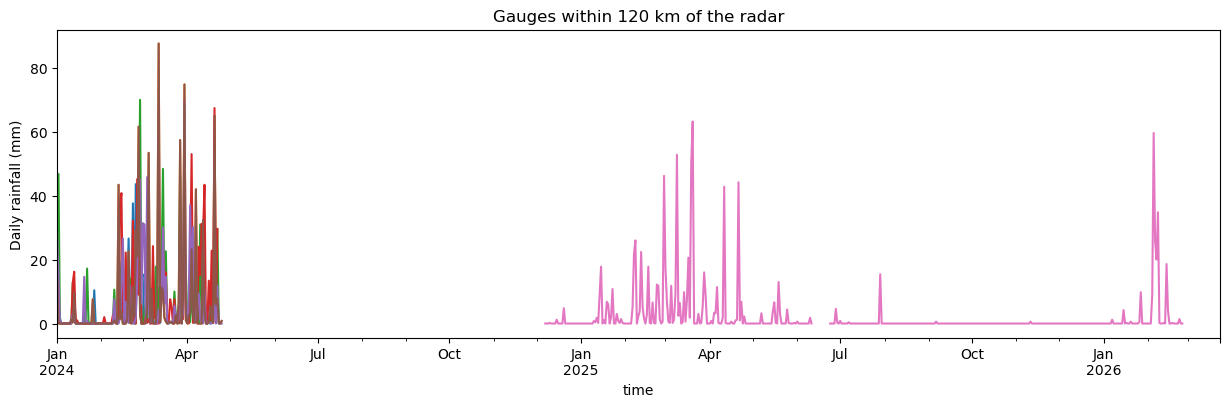

In [3]:
gauges.calc_distance_to_point((lat0, lon0))
close_gauges = gauges.metadata.loc[gauges.metadata.distance_to_point < 120]
close_gauges_data = gauges.data.loc['2024':, close_gauges.index]

min_steps_per_day = int(24 * 6 * 0.8)
df_daily_acc = close_gauges_data.resample('1D').sum(min_count=min_steps_per_day)

df_daily_acc.plot(figsize=(15, 4), legend=False)
plt.ylabel('Daily rainfall (mm)')
plt.title('Gauges within 120 km of the radar')
plt.show()

## 3. Extract and match radar at gauge locations

Keep stations with more than 15 mm on each day; match timestamps within 5 minutes.


In [4]:
def rad_vals_at_stations(ds, stations, gauges, varname='dBZ'):
    dfs = []
    for station in stations:
        point = gauges.get_coords_station(station)
        df = gutils.ds_to_df_at_point(ds, point)[[varname]]
        dfs.append(df.rename(columns={varname: f'{station}_{varname}'}))
    return pd.concat(dfs, axis=1)

In [5]:
dfs = {}

for day in df_fpaths_l1rad.index:
    date = str(day.date())
    df_close = close_gauges_data.loc[date].copy()
    stations = df_close.columns[df_close.sum() > 15].tolist()
    if not stations:
        continue

    df_close = df_close[stations]
    df_close.index = pd.to_datetime(df_close.index)

    with xr.open_dataset(df_fpaths_l1rad.loc[date, 'paths']) as ds:
        df_rad = rad_vals_at_stations(ds, stations, gauges).replace(-100, np.nan)
    df_rad.index = pd.to_datetime(df_rad.index)

    df_gauge = df_close.join(
        l2rad.calc_refl_from_rate(df_close * 6).add_suffix('_ref')
    )
    df_radar = df_rad.join(
        l2rad.calc_rate_from_refl(df_rad).add_suffix('_rate')
    )

    matched = pd.merge_asof(
        df_gauge.sort_index(), df_radar.sort_index(),
        left_index=True, right_index=True,
        direction='nearest', tolerance=pd.Timedelta('5min')
    )

    dfs[date] = {
        station: matched[
            [station, f'{station}_ref', f'{station}_dBZ', f'{station}_dBZ_rate']
        ].set_axis([
            'gauge_measurement_mm', 'ref_from_gauge_dBZ',
            'radar_measurement_dBZ', 'rate_from_rad_mmh'
        ], axis=1)
        for station in stations
    }

## 4. Inspect one station


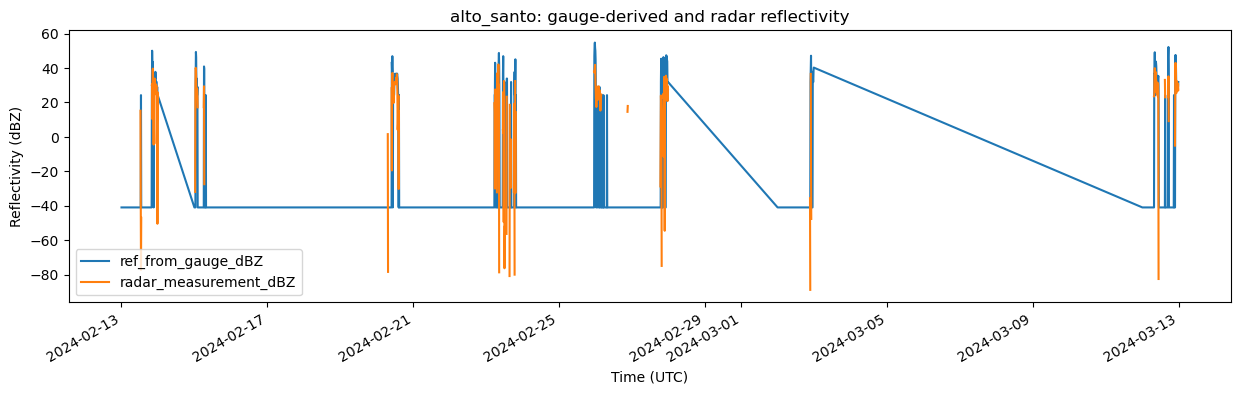

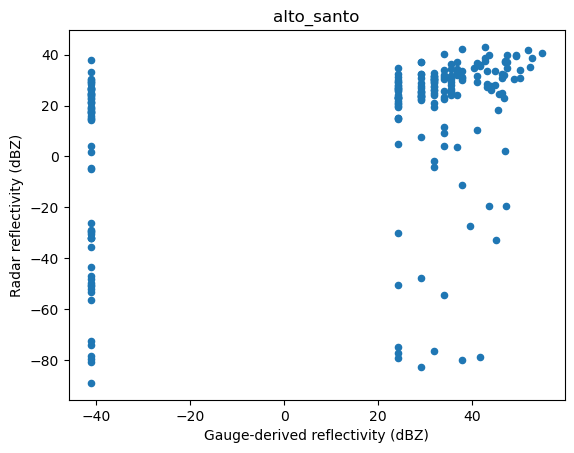

time                         
2024-02-13  rate_from_rad_mmh    0.451324
2024-02-14  rate_from_rad_mmh         NaN
2024-02-15  rate_from_rad_mmh    0.591780
2024-02-16  rate_from_rad_mmh         NaN
2024-02-17  rate_from_rad_mmh         NaN
2024-02-18  rate_from_rad_mmh         NaN
2024-02-19  rate_from_rad_mmh         NaN
2024-02-20  rate_from_rad_mmh    0.559759
2024-02-21  rate_from_rad_mmh         NaN
2024-02-22  rate_from_rad_mmh         NaN
2024-02-23  rate_from_rad_mmh    0.114726
2024-02-24  rate_from_rad_mmh         NaN
2024-02-25  rate_from_rad_mmh    0.721802
2024-02-26  rate_from_rad_mmh    0.737519
2024-02-27  rate_from_rad_mmh    0.532219
2024-02-28  rate_from_rad_mmh         NaN
2024-02-29  rate_from_rad_mmh         NaN
2024-03-01  rate_from_rad_mmh         NaN
2024-03-02  rate_from_rad_mmh    0.145428
2024-03-03  rate_from_rad_mmh         NaN
2024-03-04  rate_from_rad_mmh         NaN
2024-03-05  rate_from_rad_mmh         NaN
2024-03-06  rate_from_rad_mmh         NaN
2024

In [6]:
station = 'alto_santo'
df_station = pd.concat(
    [daily[station] for daily in dfs.values() if station in daily]
).sort_index()

df_station[['ref_from_gauge_dBZ', 'radar_measurement_dBZ']].plot(figsize=(15, 4))
plt.title(f'{station}: gauge-derived and radar reflectivity')
plt.xlabel('Time (UTC)')
plt.ylabel('Reflectivity (dBZ)')
plt.show()

df_station.plot.scatter(x='ref_from_gauge_dBZ', y='radar_measurement_dBZ')
plt.title(station)
plt.xlabel('Gauge-derived reflectivity (dBZ)')
plt.ylabel('Radar reflectivity (dBZ)')
plt.show()

daily_corr = df_station.groupby(pd.Grouper(freq='1D')).corr()
daily_corr.loc[(slice(None), 'rate_from_rad_mmh'), 'gauge_measurement_mm']

## 5. Select well-correlated station-days

Keep the existing selection: rainfall correlation > 0.7 with at least 3 paired observations.


In [7]:
# Select station-days with gauge–radar rainfall correlation > 0.7
selected = {}

for date, daily in dfs.items():
    for station, df in daily.items():
        paired = df[['gauge_measurement_mm', 'rate_from_rad_mmh']].dropna()
        if len(paired) >= 3 and paired.corr().iloc[0, 1] > 0.7:
            selected[(date, station)] = df

if selected:
    df_selected = pd.concat(selected, names=['date', 'station', 'time'])
else:
    df_selected = pd.DataFrame(columns=[
        'gauge_measurement_mm', 'ref_from_gauge_dBZ',
        'radar_measurement_dBZ', 'rate_from_rad_mmh'
    ])

df_selected


gauge_measurement_mm  \
date       station     time                                        
2024-02-13 jaguaribara 2024-02-13 00:00:00                   0.0   
                       2024-02-13 00:10:00                   0.0   
                       2024-02-13 00:20:00                   0.0   
                       2024-02-13 00:30:00                   0.0   
                       2024-02-13 00:40:00                   0.0   
...                                                          ...   
2025-03-17 morada_nova 2025-03-17 23:10:00                   0.0   
                       2025-03-17 23:20:00                   0.0   
                       2025-03-17 23:30:00                   0.0   
                       2025-03-17 23:40:00                   0.0   
                       2025-03-17 23:50:00                   0.0   

                                            ref_from_gauge_dBZ  \
date       station     time                                      
2024-02-13 jaguaribara 2024-02-13 00:00:00            -40.9897   
                       2024-02-13 00:10:00            -40.9897   
                       2024-02-13 00:20:00            -40.9897   
                       2024-02-13 00:30:00            -40.9897   
                       2024-02-13 00:40:00            -40.9897   
...                                                        ...   
2025-03-17 morada_nova 2025-03-17 23:10:00            -40.9897   
                       2025-03-17 23:20:00            -40.9897   
                       2025-03-17 23:30:00            -40.9897   
                       2025-03-17 23:40:00            -40.9897   
                       2025-03-17 23:50:00            -40.9897   

                                            radar_measurement_dBZ  \
date       station     time                                         
2024-02-13 jaguaribara 2024-02-13 00:00:00                    NaN   
                       2024-02-13 00:10:00                    NaN   
                       2024-02-13 00:20:00                    NaN   
                       2024-02-13 00:30:00                    NaN   
                       2024-02-13 00:40:00                    NaN   
...                                                           ...   
2025-03-17 morada_nova 2025-03-17 23:10:00                    NaN   
                       2025-03-17 23:20:00                    NaN   
                       2025-03-17 23:30:00                    NaN   
                       2025-03-17 23:40:00                    NaN   
                       2025-03-17 23:50:00                    NaN   

                                            rate_from_rad_mmh  
date       station     time                                    
2024-02-13 jaguaribara 2024-02-13 00:00:00                NaN  
                       2024-02-13 00:10:00                NaN  
                       2024-02-13 00:20:00                NaN  
                       2024-02-13 00:30:00                NaN  
                       2024-02-13 00:40:00                NaN  
...                                                       ...  
2025-03-17 morada_nova 2025-03-17 23:10:00                NaN  
                       2025-03-17 23:20:00                NaN  
                       2025-03-17 23:30:00                NaN  
                       2025-03-17 23:40:00                NaN  
                       2025-03-17 23:50:00                NaN  

[3024 rows x 4 columns]

## 6. Rainfall with and without the 13 dB offset

Reuse the selected station-days and the existing `calc_rate_from_refl` function. Pass the offset through its keyword; convert gauge accumulations to mm/hr with `× 6`. Plot one station on each of the first three selected days, using the same paired observations for both radar estimates.


In [8]:
offset_db = 13
rainfall = df_selected[['gauge_measurement_mm']].rename(
    columns={'gauge_measurement_mm': 'gauge_mmh'}
) * 6
radar_reflectivity = df_selected['radar_measurement_dBZ']
rainfall['radar_no_offset_mmh'] = l2rad.calc_rate_from_refl(
    radar_reflectivity, offset=0
)
rainfall['radar_offset_mmh'] = l2rad.calc_rate_from_refl(
    radar_reflectivity, offset=offset_db
)

rainfall.head()


gauge_mmh  radar_no_offset_mmh  \
date       station     time                                                  
2024-02-13 jaguaribara 2024-02-13 00:00:00        0.0                  NaN   
                       2024-02-13 00:10:00        0.0                  NaN   
                       2024-02-13 00:20:00        0.0                  NaN   
                       2024-02-13 00:30:00        0.0                  NaN   
                       2024-02-13 00:40:00        0.0                  NaN   

                                            radar_offset_mmh  
date       station     time                                   
2024-02-13 jaguaribara 2024-02-13 00:00:00               NaN  
                       2024-02-13 00:10:00               NaN  
                       2024-02-13 00:20:00               NaN  
                       2024-02-13 00:30:00               NaN  
                       2024-02-13 00:40:00               NaN

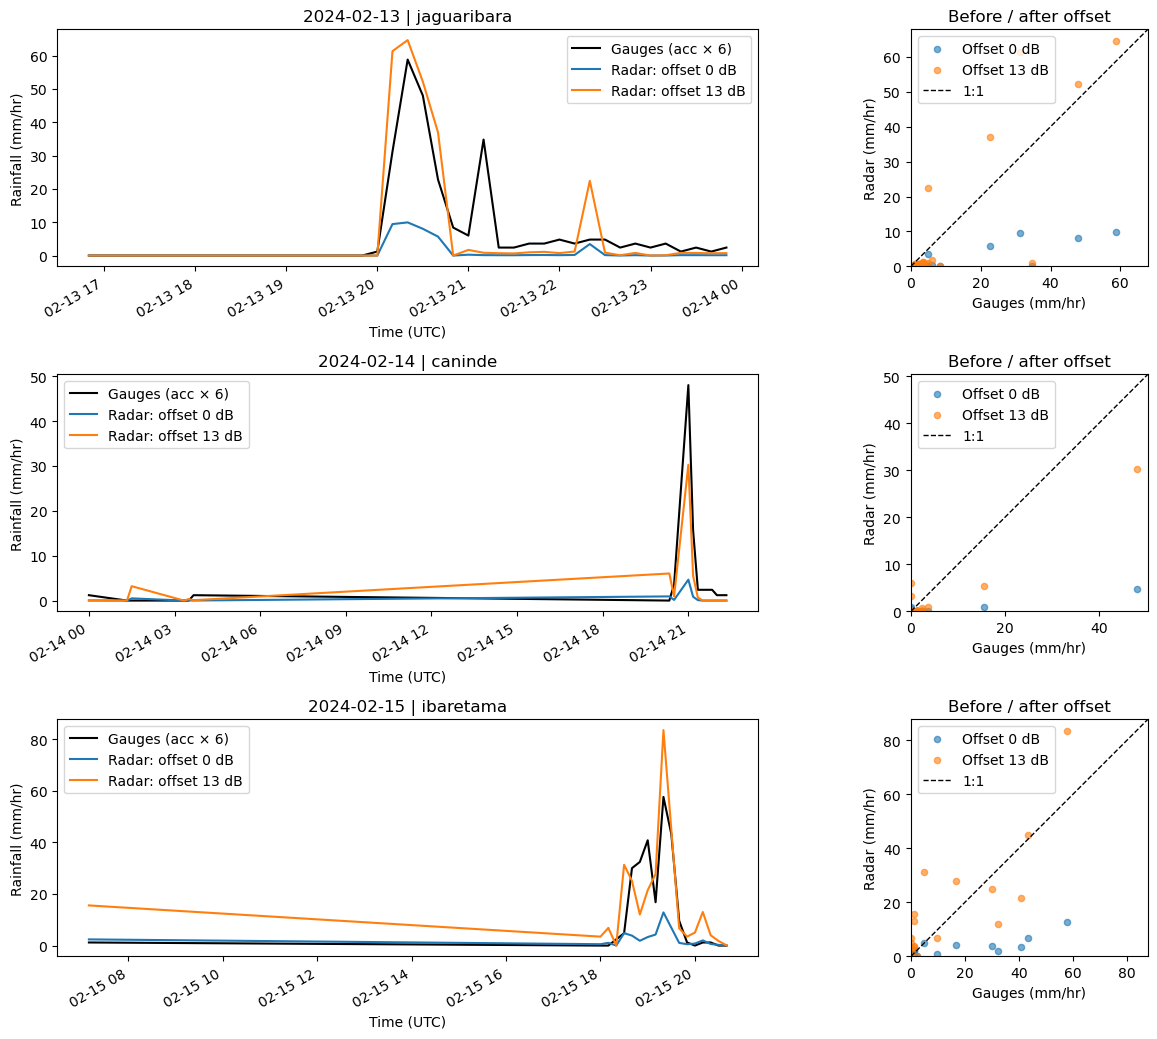

In [9]:
# One station per day, using the existing correlation-based selection.
n_days = 3
examples = []
seen_days = set()
for date, station in sorted(selected):
    if date not in seen_days:
        examples.append((date, station))
        seen_days.add(date)
    if len(examples) == n_days:
        break

if not examples:
    print('No station-days passed the correlation threshold.')
else:
    fig, axes = plt.subplots(
        len(examples), 2, figsize=(14, 3.5 * len(examples)), squeeze=False
    )
    for (date, station), (ax_time, ax_scatter) in zip(examples, axes):
        paired = rainfall.loc[(date, station)].dropna()
        paired.plot(ax=ax_time, color=['black', 'tab:blue', 'tab:orange'])
        ax_time.set(title=f'{date} | {station}', xlabel='Time (UTC)',
                    ylabel='Rainfall (mm/hr)')
        ax_time.legend(['Gauges (acc × 6)', 'Radar: offset 0 dB',
                        f'Radar: offset {offset_db} dB'])
        for column, label, color in [
            ('radar_no_offset_mmh', 'Offset 0 dB', 'tab:blue'),
            ('radar_offset_mmh', f'Offset {offset_db} dB', 'tab:orange')
        ]:
            ax_scatter.scatter(paired['gauge_mmh'], paired[column],
                               label=label, color=color, alpha=0.6, s=20)
        limit = max(1, paired.max().max()) * 1.05
        ax_scatter.plot([0, limit], [0, limit], 'k--', lw=1, label='1:1')
        ax_scatter.set(xlim=(0, limit), ylim=(0, limit),
                       xlabel='Gauges (mm/hr)', ylabel='Radar (mm/hr)',
                       title='Before / after offset')
        ax_scatter.set_aspect('equal', adjustable='box')
        ax_scatter.legend()
    fig.tight_layout()
    plt.show()


## 7. Z–Z comparison: distance and year

Gauge-derived reflectivity versus measured radar reflectivity (both in dBZ), using the same selected station-days. The dashed line is 1:1; the dotted lines mark radar = gauge ± 13 dB. In particular, points on the −13 dB line would align with 1:1 if 13 dB were added to radar reflectivity. These are reference lines, not fitted offsets.


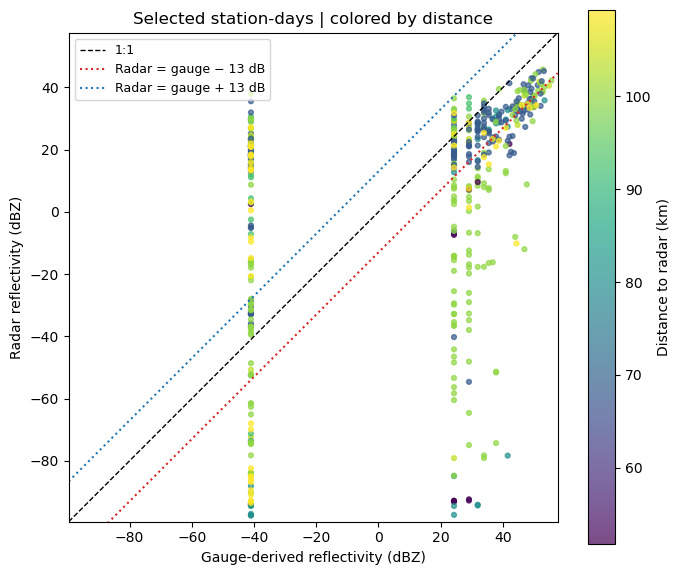

In [10]:
# Z–Z colored by distance to the radar.
zz = df_selected[['ref_from_gauge_dBZ', 'radar_measurement_dBZ']].copy()
zz = zz.replace([np.inf, -np.inf], np.nan).dropna()
if not zz.empty:
    zz['distance_km'] = zz.index.get_level_values('station').map(
        gauges.metadata['distance_to_point']
    )
    zz['year'] = pd.to_datetime(zz.index.get_level_values('time')).year


def zz_reference_lines(ax, data):
    values = data[['ref_from_gauge_dBZ', 'radar_measurement_dBZ']]
    limits = [values.min().min() - 2, values.max().max() + 2]
    x = np.array(limits)
    ax.plot(x, x, 'k--', lw=1, label='1:1')
    ax.plot(x, x - offset_db, ':', color='tab:red', lw=1.5,
            label=f'Radar = gauge − {offset_db} dB')
    ax.plot(x, x + offset_db, ':', color='tab:blue', lw=1.5,
            label=f'Radar = gauge + {offset_db} dB')
    ax.set(xlim=limits, ylim=limits,
           xlabel='Gauge-derived reflectivity (dBZ)',
           ylabel='Radar reflectivity (dBZ)')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=9)


if zz.empty:
    print('No paired reflectivity observations in the selection.')
else:
    by_distance = zz.dropna(subset=['distance_km'])
    if by_distance.empty:
        print('No distances available for the selected stations.')
    else:
        fig, ax = plt.subplots(figsize=(7, 6))
        points = ax.scatter(
            by_distance['ref_from_gauge_dBZ'], by_distance['radar_measurement_dBZ'],
            c=by_distance['distance_km'], cmap='viridis', s=12, alpha=0.7
        )
        zz_reference_lines(ax, zz)
        ax.set_title('Selected station-days | colored by distance')
        fig.colorbar(points, ax=ax, label='Distance to radar (km)')
        fig.tight_layout()
        plt.show()


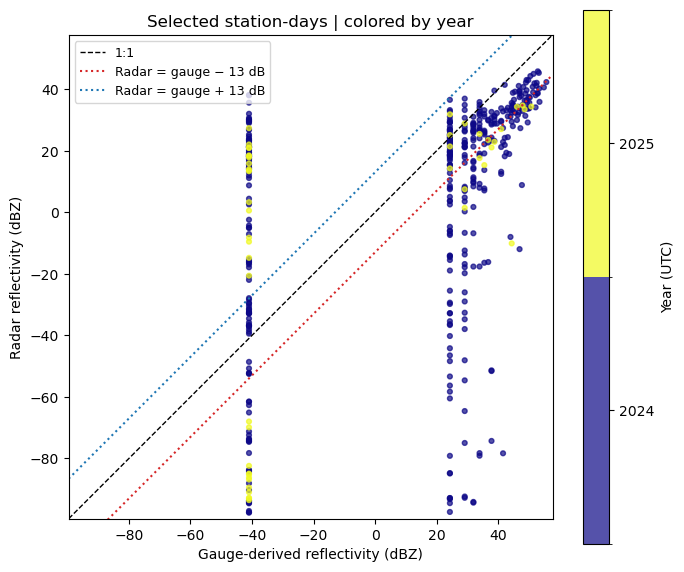

In [11]:
# Same Z–Z observations, colored by year (discrete colorbar).
from matplotlib.colors import BoundaryNorm

if zz.empty:
    print('No paired reflectivity observations in the selection.')
else:
    years = np.sort(zz['year'].unique())
    year_bins = np.arange(years.min() - 0.5, years.max() + 1.5)
    cmap = plt.get_cmap('plasma', len(year_bins) - 1)
    norm = BoundaryNorm(year_bins, cmap.N)

    fig, ax = plt.subplots(figsize=(7, 6))
    points = ax.scatter(
        zz['ref_from_gauge_dBZ'], zz['radar_measurement_dBZ'],
        c=zz['year'], cmap=cmap, norm=norm, s=12, alpha=0.7
    )
    zz_reference_lines(ax, zz)
    ax.set_title('Selected station-days | colored by year')
    fig.colorbar(points, ax=ax, ticks=years, label='Year (UTC)')
    fig.tight_layout()
    plt.show()
